In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

In [2]:
# Upload the cleaned CareFlow dataset
from google.colab import files
uploaded = files.upload()

Saving HospitalOPD_CareFlow_cleaned_v4.xlsx to HospitalOPD_CareFlow_cleaned_v4.xlsx


In [3]:
# Load the cleaned hospital dataset
file_name = list(uploaded.keys())[0]
df = pd.read_excel(file_name, sheet_name="Cleaned_Data")

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (62422, 50)


,record_no,patient_id,appointment_id,appointment_start_datetime,prescription_doctor_id,prescription_doctor_name,prescription_order_id,prescription_start_datetime,prescription_end_datetime,lab_id,...,pharmacy_end_datetime_original,pharmacy_end_datetime_parse_issue,duplicate_group_id,flag_possible_duplicate_extra,flag_lab_id_reused,flag_imaging_id_reused,flag_admin_doctor,flag_prescription_end_before_start,flag_prescription_start_missing,flag_event_before_appointment
0,1,10,445911,2026-03-30 05:36:00,225,Admin,106357,2026-03-30 05:38:00,2026-03-30 06:48:00,NaN,...,NaN,NaN,NaN,False,False,False,True,False,False,False
1,2,57,335085,2025-10-14 05:23:00,193,Dr. Abrar Ahmed Bhatti,43515,2025-10-14 05:39:00,2025-10-14 05:53:00,NaN,...,NaN,NaN,NaN,False,False,False,False,False,False,False
2,3,57,335085,2025-10-14 05:23:00,193,Dr. Abrar Ahmed Bhatti,43541,2025-10-14 06:11:00,2025-10-14 06:24:00,NaN,...,NaN,NaN,NaN,False,False,False,False,False,False,False
3,4,60,322358,2025-09-25 13:36:00,195,Dr. Anique Ahmed,34654,2025-09-25 13:50:00,2025-09-25 13:51:00,NaN,...,NaN,NaN,NaN,False,False,False,False,False,False,False
4,5,72,337714,2025-10-17 06:40:00,202,Dr. Mehreen Batool Bokhari,45263,2025-10-17 06:49:00,2025-10-17 06:49:00,NaN,...,NaN,NaN,NaN,False,False,False,False,False,False,False


In [4]:
# Check dataset columns and data types
print(df.info())
print("\nColumn names:")
print(df.columns.tolist())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 62422 entries, 0 to 62421
Data columns (total 50 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   record_no                                62422 non-null  int64  
 1   patient_id                               62422 non-null  int64  
 2   appointment_id                           62422 non-null  int64  
 3   appointment_start_datetime               62422 non-null  object 
 4   prescription_doctor_id                   62422 non-null  int64  
 5   prescription_doctor_name                 62422 non-null  object 
 6   prescription_order_id                    62422 non-null  int64  
 7   prescription_start_datetime              62410 non-null  object 
 8   prescription_end_datetime                62421 non-null  object 
 9   lab_id                                   18029 non-null  float64
 10  lab_name                                 18029

In [5]:
# Check missing values and duplicate records
print("Total duplicate rows:", df.duplicated().sum())

missing_report = df.isnull().sum().reset_index()
missing_report.columns = ["Column", "Missing_Values"]
missing_report = missing_report[missing_report["Missing_Values"] > 0]

display(missing_report)

Total duplicate rows: 0


,Column,Missing_Values
7,prescription_start_datetime,12
8,prescription_end_datetime,1
9,lab_id,44393
10,lab_name,44393
11,lab_start_datetime,44393
12,lab_end_datetime,49095
13,imaging_request_id,56899
14,imaging_result_id,56899
15,imaging_name,56899
16,imaging_start_datetime,56899


In [6]:
# Convert appointment date into datetime format
df["appointment_start_datetime"] = pd.to_datetime(
    df["appointment_start_datetime"],
    format="mixed",
    errors="coerce"
)

df["appointment_month"] = df["appointment_start_datetime"].dt.to_period("M").astype(str)

print("Date conversion completed")

Date conversion completed


In [7]:
# Generate overall patient and appointment summary
overall_summary = pd.DataFrame({
    "Metric": [
        "Total Records",
        "Unique Patients",
        "Unique Appointments",
        "Unique Workflow Types",
        "Missing Appointment Dates"
    ],
    "Value": [
        len(df),
        df["patient_id"].nunique(),
        df["appointment_id"].nunique(),
        df["flow_name"].nunique(),
        df["appointment_start_datetime"].isnull().sum()
    ]
})

display(overall_summary)

,Metric,Value
0,Total Records,62422
1,Unique Patients,39442
2,Unique Appointments,49912
3,Unique Workflow Types,7
4,Missing Appointment Dates,0


In [8]:
# Analyse hospital workflow distribution
workflow_summary = df.groupby("flow_name").agg(
    Total_Records=("record_no", "count"),
    Unique_Patients=("patient_id", "nunique"),
    Unique_Appointments=("appointment_id", "nunique")
).reset_index()

workflow_summary = workflow_summary.sort_values(
    by="Total_Records", ascending=False
)

display(workflow_summary)

,flow_name,Total_Records,Unique_Patients,Unique_Appointments
0,Appointment → Prescription,40164,33081,39697
3,Appointment → Prescription → Lab,16434,5627,6003
1,Appointment → Prescription → Imaging,3947,3035,3804
4,Appointment → Prescription → Lab + Imaging,1575,1396,1528
6,Appointment → Prescription → Pharmacy,281,104,104
5,Appointment → Prescription → Lab + Pharmacy,20,14,14
2,Appointment → Prescription → Imaging + Pharmacy,1,1,1


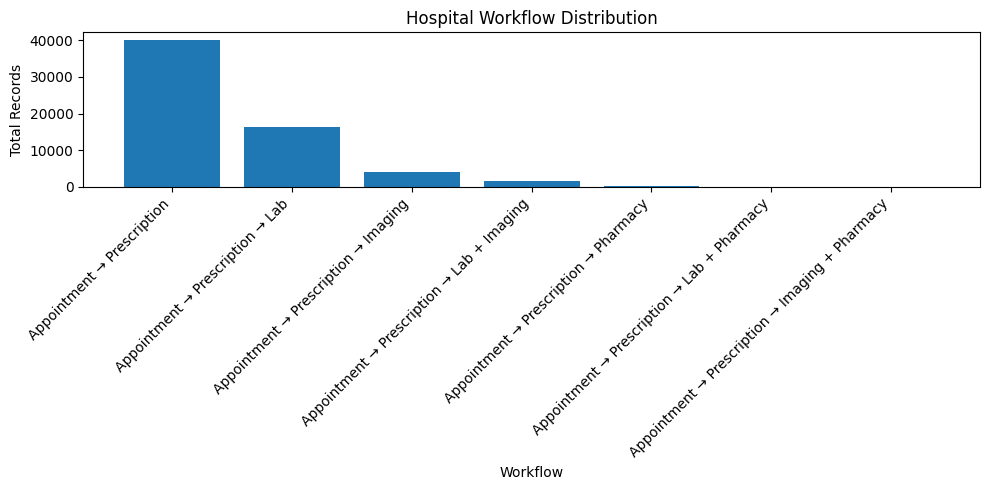

In [9]:
# Visualize hospital workflow distribution
plt.figure(figsize=(10, 5))
plt.bar(workflow_summary["flow_name"], workflow_summary["Total_Records"])
plt.title("Hospital Workflow Distribution")
plt.xlabel("Workflow")
plt.ylabel("Total Records")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [10]:
# Calculate monthly appointment trends
monthly_appointments = df.dropna(
    subset=["appointment_start_datetime"]
).groupby("appointment_month").agg(
    Total_Appointments=("appointment_id", "nunique"),
    Total_Patients=("patient_id", "nunique")
).reset_index()

display(monthly_appointments)

,appointment_month,Total_Appointments,Total_Patients
0,2024-04,4,4
1,2024-05,2,2
2,2024-06,2,2
3,2024-07,2,2
4,2024-08,1,1
5,2024-10,1,1
6,2024-11,1,1
7,2024-12,3,3
8,2025-02,4,4
9,2025-03,27,26


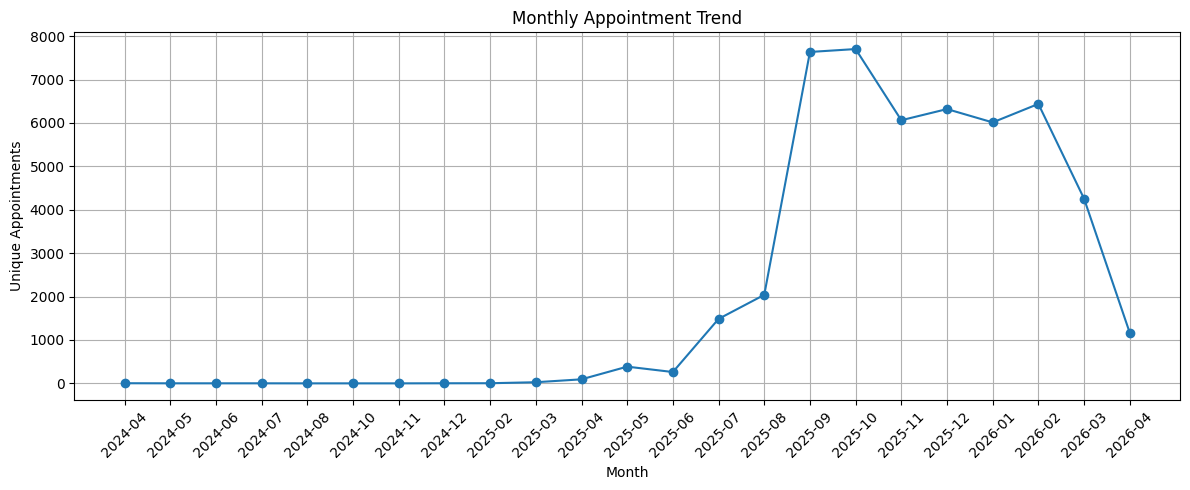

In [11]:
# Visualize monthly appointment trends
plt.figure(figsize=(12, 5))
plt.plot(
    monthly_appointments["appointment_month"],
    monthly_appointments["Total_Appointments"],
    marker="o"
)
plt.title("Monthly Appointment Trend")
plt.xlabel("Month")
plt.ylabel("Unique Appointments")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [12]:
# Calculate unique patients in each workflow
patient_workflow = df.groupby("flow_name")["patient_id"].nunique().sort_values(
    ascending=False
)

display(patient_workflow.reset_index(name="Unique_Patients"))

,flow_name,Unique_Patients
0,Appointment → Prescription,33081
1,Appointment → Prescription → Lab,5627
2,Appointment → Prescription → Imaging,3035
3,Appointment → Prescription → Lab + Imaging,1396
4,Appointment → Prescription → Pharmacy,104
5,Appointment → Prescription → Lab + Pharmacy,14
6,Appointment → Prescription → Imaging + Pharmacy,1


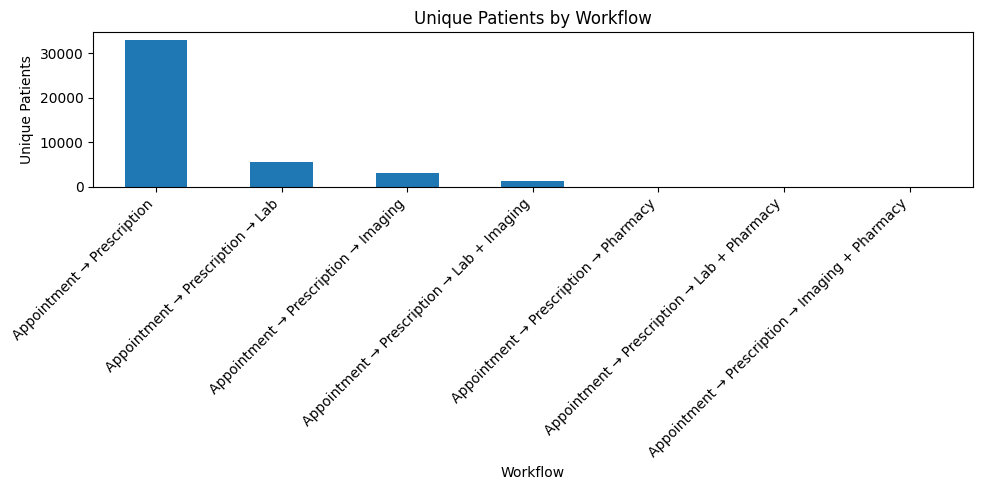

In [13]:
# Visualize patient distribution by workflow
plt.figure(figsize=(10, 5))
patient_workflow.plot(kind="bar")
plt.title("Unique Patients by Workflow")
plt.xlabel("Workflow")
plt.ylabel("Unique Patients")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [14]:
# Summarize data quality flags
quality_columns = [
    "flag_possible_duplicate_extra",
    "flag_lab_id_reused",
    "flag_imaging_id_reused",
    "flag_admin_doctor",
    "flag_prescription_end_before_start",
    "flag_prescription_start_missing",
    "flag_event_before_appointment"
]

quality_summary = []

for col in quality_columns:
    if col in df.columns:
        flagged = df[col].astype(str).str.lower().isin(
            ["true", "1", "yes"]
        ).sum()

        quality_summary.append({
            "Quality_Flag": col,
            "Flagged_Records": flagged
        })

quality_report = pd.DataFrame(quality_summary)
display(quality_report)

,Quality_Flag,Flagged_Records
0,flag_possible_duplicate_extra,4
1,flag_lab_id_reused,1332
2,flag_imaging_id_reused,121
3,flag_admin_doctor,3
4,flag_prescription_end_before_start,52
5,flag_prescription_start_missing,12
6,flag_event_before_appointment,749


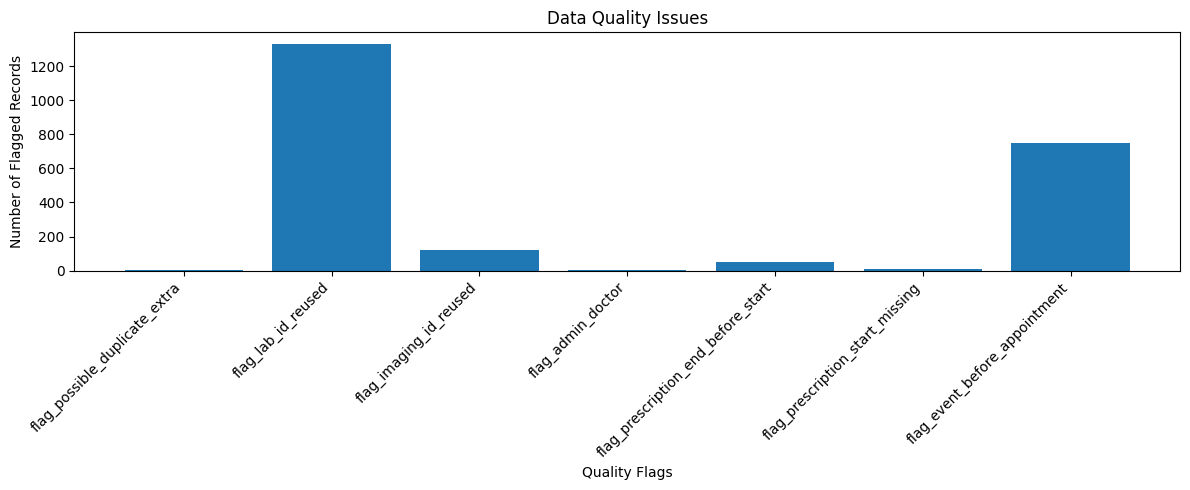

In [15]:
# Visualize data quality issues
plt.figure(figsize=(12, 5))
plt.bar(
    quality_report["Quality_Flag"],
    quality_report["Flagged_Records"]
)
plt.title("Data Quality Issues")
plt.xlabel("Quality Flags")
plt.ylabel("Number of Flagged Records")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

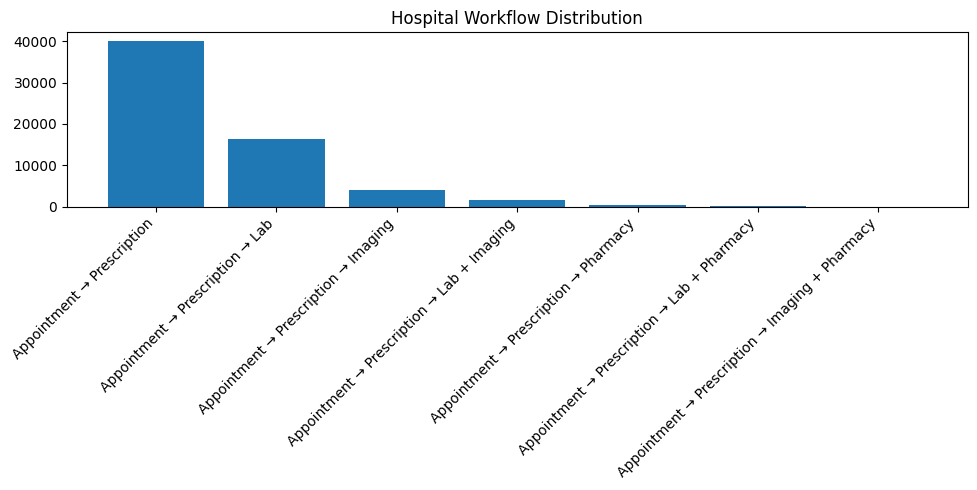

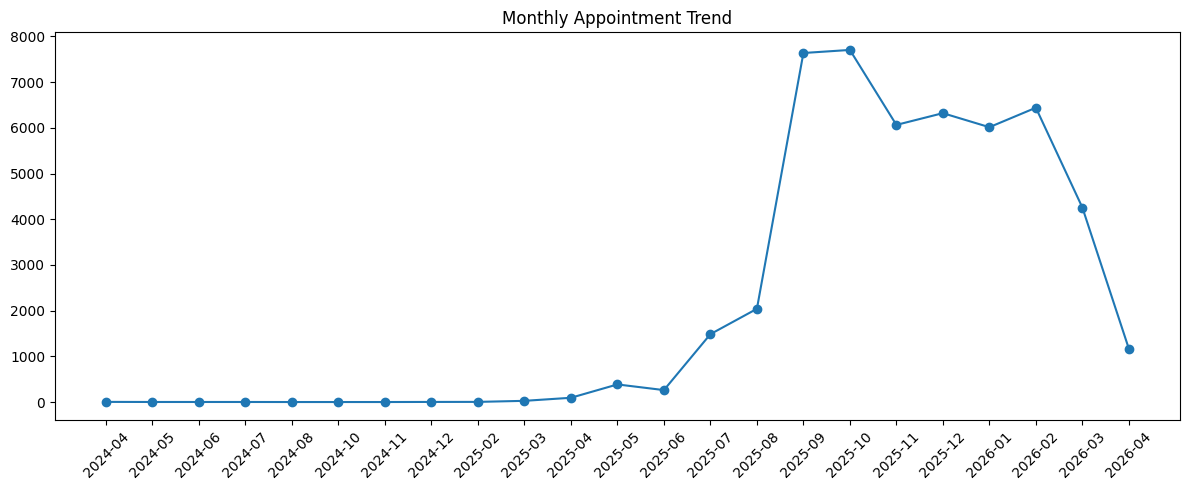

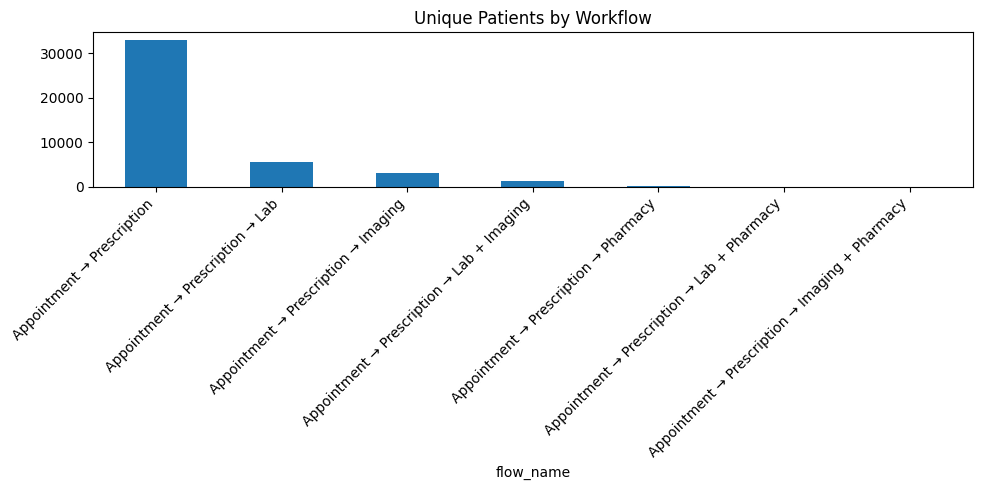

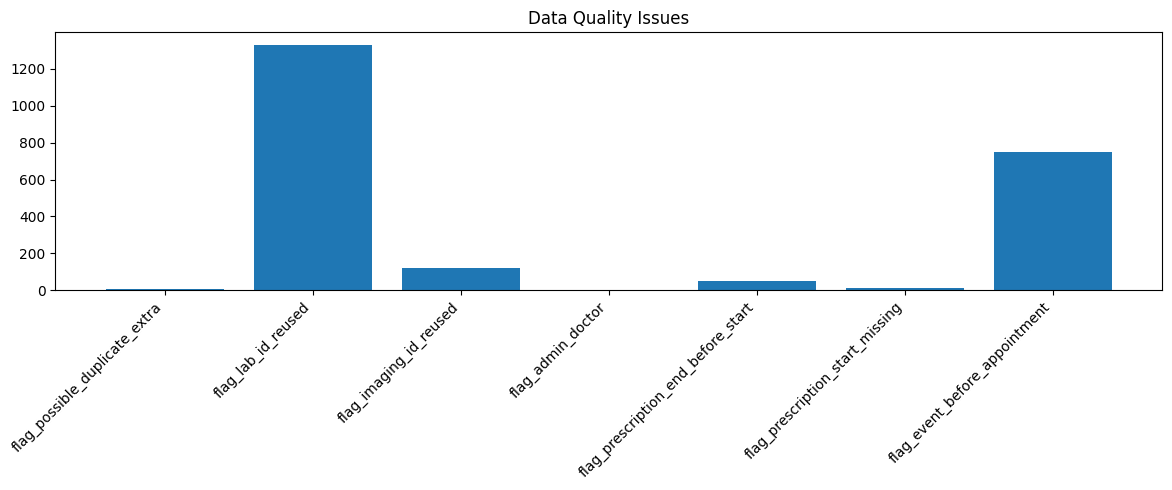

In [21]:

# Save all analysis charts
os.makedirs("Analysis_Output", exist_ok=True)

plt.figure(figsize=(10, 5))
plt.bar(workflow_summary["flow_name"], workflow_summary["Total_Records"])
plt.title("Hospital Workflow Distribution")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("Analysis_Output/01_workflow_distribution.png")
plt.show()

plt.figure(figsize=(12, 5))
plt.plot(monthly_appointments["appointment_month"],
         monthly_appointments["Total_Appointments"], marker="o")
plt.title("Monthly Appointment Trend")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("Analysis_Output/02_monthly_appointments.png")
plt.show()

plt.figure(figsize=(10, 5))
patient_workflow.plot(kind="bar")
plt.title("Unique Patients by Workflow")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("Analysis_Output/03_patient_workflow.png")
plt.show()

plt.figure(figsize=(12, 5))
plt.bar(quality_report["Quality_Flag"], quality_report["Flagged_Records"])
plt.title("Data Quality Issues")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("Analysis_Output/04_data_quality.png")
plt.show()


In [22]:

# Export analysis summary reports

overall_summary.to_csv("Analysis_Output/overall_summary.csv", index=False)
workflow_summary.to_csv("Analysis_Output/workflow_summary.csv", index=False)
monthly_appointments.to_csv("Analysis_Output/monthly_appointments.csv", index=False)
quality_report.to_csv("Analysis_Output/data_quality_report.csv", index=False)

print("Summary reports saved successfully!")


Summary reports saved successfully!


In [23]:

# Download analysis files
from google.colab import files
import os

for file_name in os.listdir("Analysis_Output"):
    file_path = os.path.join("Analysis_Output", file_name)
    files.download(file_path)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (6 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [24]:

#  CREATE ZIP OF ALL ANALYSIS OUTPUTS

import shutil
from google.colab import files

shutil.make_archive(
    "Analysis_Output",
    "zip",
    "Analysis_Output"
)

files.download("Analysis_Output.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>